In [2]:
!pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=9642c99621627c4ba1e04f27b9cd80de8d7efbec2eca04692c767941ba6e39f1
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [3]:
import os, re, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")

OUT_DIR       = "."
RANDOM_STATE  = 42
SENSITIVE     = ["age", "personal_status", "foreign_worker"]
PREFERRED_TEST_POSITION = 23

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)
R = {}
print("shap", shap.__version__, "| output folder:", os.path.abspath(OUT_DIR))

shap 0.54.1 | output folder: /content


In [5]:
def load_german_credit():
    for p in ["german_credit.csv", "data/german_credit.csv", "../german_credit.csv",
              os.path.join(OUT_DIR, "german_credit.csv"), "/mnt/data/german_credit.csv"]:
        if os.path.exists(p):
            print("Loaded local file:", p)
            return pd.read_csv(p), p

    from sklearn.datasets import fetch_openml
    d = fetch_openml("credit-g", version=1, as_frame=True)
    print("Loaded German Credit from OpenML (credit-g)")
    return d.frame.copy(), "OpenML credit-g"


df, DATA_SOURCE = load_german_credit()
df.columns = [c.strip() for c in df.columns]
print("Shape:", df.shape)
df.head()

Loaded German Credit from OpenML (credit-g)
Shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [6]:
target_candidates = ["class", "target", "credit_risk", "risk", "default", "label", "y"]
lower_map = {c.lower(): c for c in df.columns}
target_col = next((lower_map[t] for t in target_candidates if t in lower_map), df.columns[-1])

t = df[target_col]
if not pd.api.types.is_numeric_dtype(t):
    y = (t.astype(str).str.strip().str.lower() == "bad").astype(int)
else:
    vals = set(pd.unique(t))
    if vals == {1, 2}:            # UCI numeric coding: 1 = good, 2 = bad
        y = (t == 2).astype(int)
    else:                         # 0/1 coding: assume 1 = bad / default
        y = t.astype(int)
        print("NOTE: numeric 0/1 target assumed to have 1 = bad.")

X = df.drop(columns=[target_col]).copy()
cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in X.columns if c not in cat_cols]
feature_names = X.columns.tolist()

print("Target column :", target_col, "| bad (1) =", int(y.sum()), "| good (0) =", int((1 - y).sum()),
      f"| bad rate = {y.mean():.2%}")
print("Categorical   :", len(cat_cols), "columns")
print("Numerical     :", len(num_cols), "columns ->", num_cols)

Target column : class | bad (1) = 300 | good (0) = 700 | bad rate = 30.00%
Categorical   : 13 columns
Numerical     : 7 columns -> ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']


In [7]:
enc = OrdinalEncoder()
X_enc = X.copy()
X_enc[cat_cols] = enc.fit_transform(X[cat_cols].astype(str))
X_enc = X_enc.astype(float)
categories = {c: list(cats) for c, cats in zip(cat_cols, enc.categories_)}   # code -> original label

def label_of(feat, code):
    """Human-readable value of an encoded feature (e.g. checking_status 0 -> '<0')."""
    if feat in categories:
        return str(categories[feat][int(round(code))])
    return str(int(code)) if float(code).is_integer() else f"{code:.2f}"

# ---- stratified 80:20 split ----
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print(f"Bad rate  train = {y_train.mean():.3f} | test = {y_test.mean():.3f}   (stratified -> equal)")
R.update(dataset=DATA_SOURCE, n_rows=len(df), n_features=len(feature_names),
         n_train=len(X_train), n_test=len(X_test))

Train: (800, 20)  Test: (200, 20)
Bad rate  train = 0.300 | test = 0.300   (stratified -> equal)


In [8]:
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
assert list(rf.classes_) == [0, 1]

proba_test = rf.predict_proba(X_test)[:, 1]
pred_test  = (proba_test >= 0.5).astype(int)
acc = accuracy_score(y_test, pred_test)
auc = roc_auc_score(y_test, proba_test)
R.update(acc=acc, auc=auc)

print("Model : RandomForest (200 trees, depth 8)")
print(f"Test accuracy : {acc:.2f}      ROC-AUC : {auc:.2f}")
print(f"Predicted bad (rejected) in test set: {pred_test.sum()} of {len(pred_test)}")

Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.77      ROC-AUC : 0.83
Predicted bad (rejected) in test set: 29 of 200


In [9]:
explainer = shap.TreeExplainer(rf)
sv_raw = explainer.shap_values(X_test)

def bad_class(arr):
    """Return the (n_samples, n_features) array for class 1 = bad, for any SHAP version."""
    if isinstance(arr, list):                 # older SHAP: list [class0, class1]
        return np.asarray(arr[1])
    arr = np.asarray(arr)
    if arr.ndim == 3:                         # newer SHAP: (n, features, classes)
        return arr[:, :, 1]
    return arr

sv_bad = bad_class(sv_raw)
ev = np.atleast_1d(explainer.expected_value)
base_value = float(ev[1] if len(ev) > 1 else ev[0])      # average P(bad) the model starts from
assert sv_bad.shape == X_test.shape, sv_bad.shape

mean_abs = np.abs(sv_bad).mean(axis=0)
imp = (pd.DataFrame({"FEATURE": feature_names, "MEAN|SHAP|": mean_abs})
         .sort_values("MEAN|SHAP|", ascending=False).reset_index(drop=True))
imp.index = imp.index + 1
top5 = imp.head(5)
R["top5"] = list(zip(top5["FEATURE"], top5["MEAN|SHAP|"]))

print("GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print("RANK  FEATURE              MEAN|SHAP|")
print("-" * 39)
for r, (f, v) in zip(top5.index, R["top5"]):
    print(f"{r:>2}    {f:<20} {v:.3f}")
print("-" * 39)

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE              MEAN|SHAP|
---------------------------------------
 1    checking_status      0.092
 2    duration             0.042
 3    credit_amount        0.027
 4    savings_status       0.027
 5    purpose              0.025
---------------------------------------


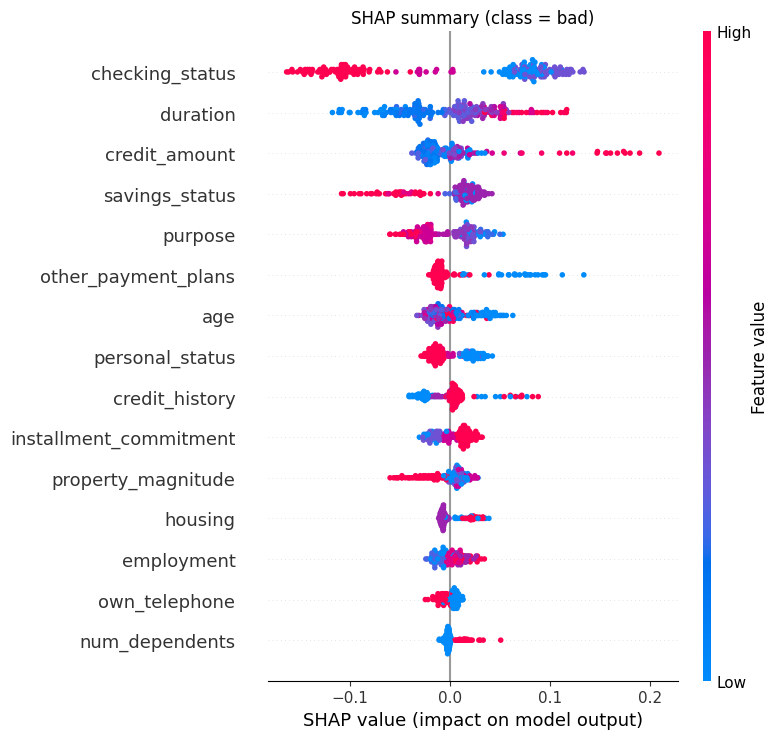

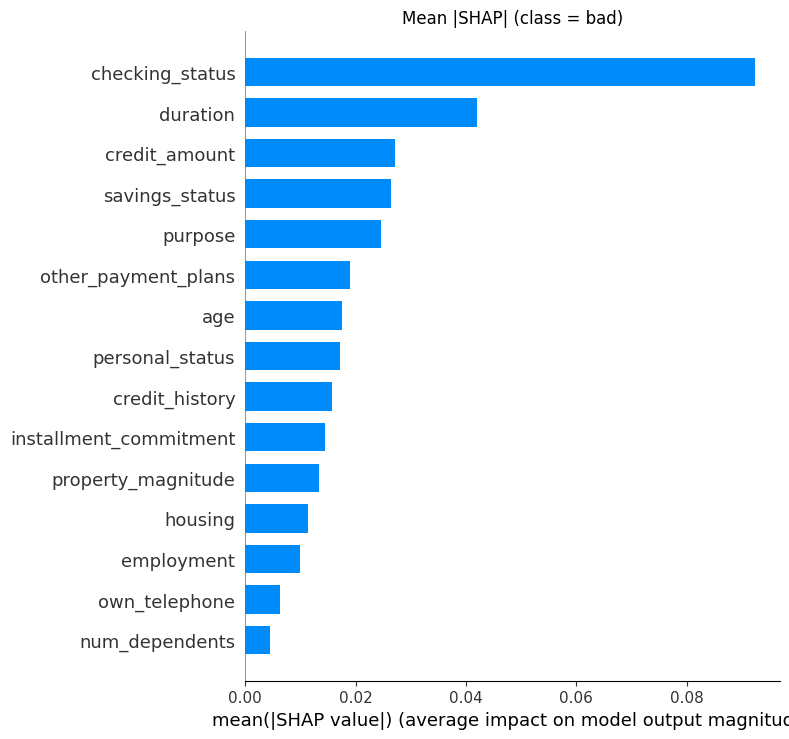

Plot saved : shap_summary.png, shap_bar.png


In [10]:
# ---- SUMMARY (beeswarm) plot -> shap_summary.png ----
plt.figure()
shap.summary_plot(sv_bad, X_test, feature_names=feature_names, show=False, max_display=15)
plt.title("SHAP summary (class = bad)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "shap_summary.png"), dpi=150, bbox_inches="tight")
plt.show()

# ---- BAR plot (mean |SHAP|) -> shap_bar.png ----
plt.figure()
shap.summary_plot(sv_bad, X_test, feature_names=feature_names, plot_type="bar", show=False, max_display=15)
plt.title("Mean |SHAP| (class = bad)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "shap_bar.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved : shap_summary.png, shap_bar.png")

## Task 4 — SHAP waterfall for one rejected applicant


In [11]:
rejected_pos = np.where(pred_test == 1)[0]                  # positions in the test set predicted bad
assert len(rejected_pos), "No rejected applicant found in the test set."
pos = PREFERRED_TEST_POSITION if PREFERRED_TEST_POSITION in rejected_pos else int(rejected_pos[0])
# To explain a different applicant just set: pos = <any value from rejected_pos>

x_row   = X_test.iloc[pos]
orig_ix = X_test.index[pos]
p_bad   = float(proba_test[pos])
sv_i    = sv_bad[pos]
print(f"Applicant (test index {pos}, dataset row {orig_ix}) : P(bad) = {p_bad:.2f}  ->  "
      f"{'REJECTED' if p_bad >= 0.5 else 'APPROVED'}   (base value = {base_value:.2f})")

def reason_text(i):
    f = feature_names[i]
    return f"{f}={label_of(f, x_row.iloc[i])}"

order_abs = np.argsort(-np.abs(sv_i))
shap_top3 = [int(i) for i in order_abs[:3]]
print("\nTop 3 SHAP reasons (by |SHAP|):")
for k, i in enumerate(shap_top3, 1):
    print(f"  {k}. {reason_text(i):<40} SHAP = {sv_i[i]:+.3f}  "
          f"({'raises' if sv_i[i] > 0 else 'lowers'} risk of 'bad')")

R.update(pos=pos, orig_ix=orig_ix, p_bad=p_bad, base_value=base_value,
         shap_top3=[(reason_text(i), float(sv_i[i])) for i in shap_top3])

Applicant (test index 23, dataset row 570) : P(bad) = 0.57  ->  REJECTED   (base value = 0.30)

Top 3 SHAP reasons (by |SHAP|):
  1. checking_status=<0                       SHAP = +0.110  (raises risk of 'bad')
  2. duration=24                              SHAP = +0.056  (raises risk of 'bad')
  3. personal_status=female div/dep/mar       SHAP = +0.038  (raises risk of 'bad')


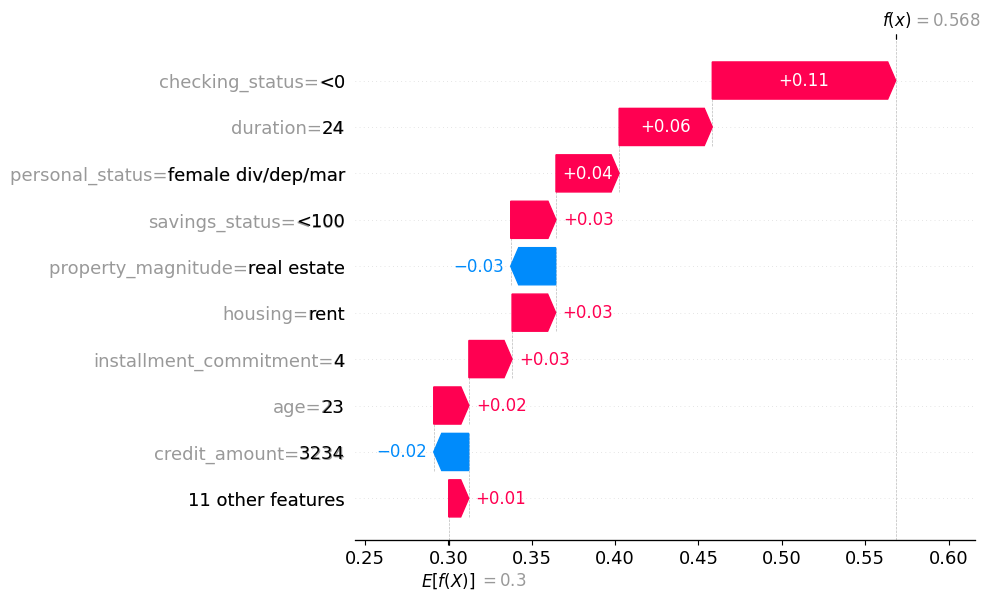

Plot saved : shap_waterfall.png


In [12]:
# ---- waterfall plot -> shap_waterfall.png ----
disp_names = [reason_text(i) for i in range(len(feature_names))]
try:
    exp = shap.Explanation(values=sv_i, base_values=base_value, data=None, feature_names=disp_names)
    shap.plots.waterfall(exp, max_display=10, show=False)
except Exception:
    exp = shap.Explanation(values=sv_i, base_values=base_value, data=x_row.values, feature_names=feature_names)
    shap.plots.waterfall(exp, max_display=10, show=False)
plt.gcf().savefig(os.path.join(OUT_DIR, "shap_waterfall.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved : shap_waterfall.png")

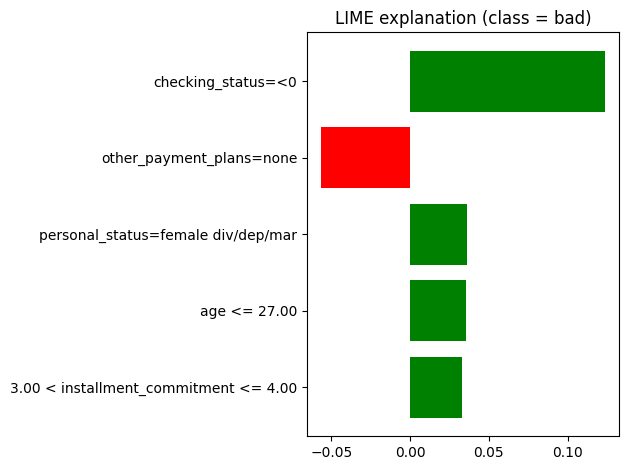

In [13]:
cat_idx = [feature_names.index(c) for c in cat_cols]
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=["good", "bad"],
    categorical_features=cat_idx,
    categorical_names={feature_names.index(c): categories[c] for c in cat_cols},
    mode="classification",
    discretize_continuous=True,
    random_state=RANDOM_STATE)

predict_fn = lambda a: rf.predict_proba(pd.DataFrame(a, columns=feature_names))
lime_exp = lime_explainer.explain_instance(x_row.values, predict_fn, num_features=5, labels=(1,))

lime_texts   = [t for t, w in lime_exp.as_list(label=1)]
lime_idx     = [i for i, w in lime_exp.as_map()[1]]
lime_weights = [w for t, w in lime_exp.as_list(label=1)]
lime_rank = sorted(zip(lime_idx, lime_texts, lime_weights), key=lambda z: -abs(z[2]))   # strongest first
lime_top3 = [i for i, _, _ in lime_rank[:3]]

fig = lime_exp.as_pyplot_figure(label=1)
plt.title("LIME explanation (class = bad)")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "lime_explanation.png"), dpi=150, bbox_inches="tight")
plt.show()
try:
    lime_exp.save_to_file(os.path.join(OUT_DIR, "lime_explanation.html"))
except Exception:
    pass

In [14]:
# ---- side-by-side comparison table (Part B format) ----
shap_lines = [f"{reason_text(i)}  {sv_i[i]:+.2f}" for i in shap_top3]
lime_lines = [f"{t}  {w:+.2f}" for _, t, w in lime_rank]

print(f"Applicant (test index {pos}) : P(bad) = {p_bad:.2f}  ->  REJECTED\n")
print(f"{'SHAP (top 3)':<46}LIME (top 5)")
print("-" * 95)
for k in range(max(len(shap_lines), len(lime_lines))):
    left  = shap_lines[k] if k < len(shap_lines) else ""
    right = lime_lines[k] if k < len(lime_lines) else ""
    print(f"{left:<46}{right}")
print("-" * 95)

agree_feats = [feature_names[i] for i in shap_top3 if i in lime_top3]
n_agree = len(agree_feats)
print(f"Top-3 agreement (SHAP vs LIME) : {n_agree} / 3   -> agreeing features: {agree_feats if agree_feats else 'none'}")
print("LIME top-3 features:", [feature_names[i] for i in lime_top3])
print("SHAP top-3 features:", [feature_names[i] for i in shap_top3])

R.update(lime_rank=[(feature_names[i], t, float(w)) for i, t, w in lime_rank],
         n_agree=n_agree, agree_feats=agree_feats,
         lime_top3=[feature_names[i] for i in lime_top3])

Applicant (test index 23) : P(bad) = 0.57  ->  REJECTED

SHAP (top 3)                                  LIME (top 5)
-----------------------------------------------------------------------------------------------
checking_status=<0  +0.11                     checking_status=<0  +0.12
duration=24  +0.06                            other_payment_plans=none  -0.06
personal_status=female div/dep/mar  +0.04     personal_status=female div/dep/mar  +0.04
                                              age <= 27.00  +0.04
                                              3.00 < installment_commitment <= 4.00  +0.03
-----------------------------------------------------------------------------------------------
Top-3 agreement (SHAP vs LIME) : 2 / 3   -> agreeing features: ['checking_status', 'personal_status']
LIME top-3 features: ['checking_status', 'other_payment_plans', 'personal_status']
SHAP top-3 features: ['checking_status', 'duration', 'personal_status']


In [15]:
# ---- 1. sensitive attribute check (SHAP top-3 + LIME top-5) ----
reason_idx = list(dict.fromkeys(shap_top3 + [i for i, _, _ in lime_rank]))     # unique, order kept
reason_feats = [feature_names[i] for i in reason_idx]
sens_found = [f for f in reason_feats if f in SENSITIVE]
status = "REVIEW" if sens_found else "OK"
print("Sensitive attributes in reasons :", ", ".join(sens_found) if sens_found else "none", "->", status)
R.update(sens_found=sens_found, sens_status=status)

Sensitive attributes in reasons : personal_status, age -> REVIEW


In [16]:
# ---- 2. plain-language templates (feature -> sentence fragment) ----
def phrase(feat, val_label, raw):
    T = {
        "checking_status":       lambda: ("your current account balance is negative" if val_label.strip().startswith("<0")
                                          else f"your checking account status ({val_label}) is considered risky"),
        "duration":              lambda: f"the requested duration ({int(raw)} months) is long",
        "credit_amount":         lambda: f"the requested credit amount ({int(raw)}) is high",
        "savings_status":        lambda: f"your savings balance ({val_label}) is low",
        "credit_history":        lambda: f"your past credit history ({val_label}) shows repayment concerns",
        "purpose":               lambda: f"the purpose of the purchase ({val_label}) carries higher risk",
        "employment":            lambda: f"your length of current employment ({val_label}) is short",
        "installment_commitment":lambda: "the instalment would take a large share of your income",
        "other_payment_plans":   lambda: f"you have other payment plans ({val_label})",
        "property_magnitude":    lambda: f"the property you own ({val_label}) offers limited security",
        "housing":               lambda: f"your housing situation ({val_label}) adds risk",
        "existing_credits":      lambda: "you already hold several existing credits",
        "job":                   lambda: f"your job category ({val_label}) is considered higher risk",
        "other_parties":         lambda: f"there is no co-applicant/guarantor ({val_label})",
        "residence_since":       lambda: "you have lived at your present address for a short time",
        "own_telephone":         lambda: "no registered telephone is on record",
        "num_dependents":        lambda: "the number of dependants is high",
    }
    return T[feat]() if feat in T else f"'{feat}' ({val_label}) increased the estimated risk"

# SHAP features that push towards 'bad' (positive SHAP), strongest first, non-sensitive only
pos_rank = [int(i) for i in np.argsort(-sv_i) if sv_i[i] > 0]
legit = [i for i in pos_rank if feature_names[i] not in SENSITIVE][:2]

parts = [phrase(feature_names[i], label_of(feature_names[i], x_row.iloc[i]), x_row.iloc[i]) for i in legit]
reasons_sentence = " and ".join(parts) if parts else "the overall risk assessment was high"
message = f"Your EMI request was not approved mainly because {reasons_sentence}."

print("Message (legitimate reasons only):")
print(textwrap.fill('"' + message + '"', 70))
print("\nFeatures used in message:", [feature_names[i] for i in legit])
R.update(message=message, legit_feats=[feature_names[i] for i in legit])

Message (legitimate reasons only):
"Your EMI request was not approved mainly because your current account
balance is negative and the requested duration (24 months) is long."

Features used in message: ['checking_status', 'duration']
